In [0]:
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from pyspark.sql import functions as F
from sklearn.ensemble import IsolationForest

# 1. Δημιουργία οικονομικών δεδομένων συναλλαγών & μετατροπή σε Spark DataFrame
np.random.seed(42)
timestamps = pd.date_range('2026-01-01', periods=2000, freq='15min')
amounts = np.random.normal(loc=100.0, scale=15.0, size=2000)

# Προσθήκη 20 τεχνητών ανωμαλιών (απότομες αιχμές)
anomaly_indices = np.random.choice(range(2000), size=20, replace=False)
amounts[anomaly_indices] = amounts[anomaly_indices] * np.random.uniform(3.5, 6.0, size=20)

pdf = pd.DataFrame({'timestamp': timestamps, 'transaction_volume': np.round(amounts, 2)})
spark_df = spark.createDataFrame(pdf)

# 2. PySpark Transformations & Αποθήκευση ως Delta Table
spark_df_transformed = (
    spark_df
    .withColumn("hour", F.hour("timestamp"))
    .withColumn("is_high_volume", F.when(F.col("transaction_volume") > 200, 1).otherwise(0))
)

spark_df_transformed.write.format("delta").mode("overwrite").saveAsTable("financial_ts_delta")
print("Ο πίνακας Delta 'financial_ts_delta' δημιουργήθηκε επιτυχώς!")

# 3. Εκπαίδευση Isolation Forest & Καταγραφή με MLflow
data_for_ml = spark.table("financial_ts_delta").toPandas()

with mlflow.start_run(run_name="TimeSeries_Anomaly_Detection"):
    contamination_rate = 0.015
    iso_forest = IsolationForest(contamination=contamination_rate, random_state=42)
    
    data_for_ml['anomaly_score'] = iso_forest.fit_predict(data_for_ml[['transaction_volume', 'hour']])
    # -1 σημαίνει ανωμαλία, 1 σημαίνει κανονικό
    anomalies_found = int((data_for_ml['anomaly_score'] == -1).sum())
    
    # Καταγραφή παραμέτρων και μετρικών στο Databricks MLflow
    mlflow.log_param("model_type", "IsolationForest")
    mlflow.log_param("contamination", contamination_rate)
    mlflow.log_metric("anomalies_detected", anomalies_found)
    mlflow.sklearn.log_model(iso_forest, "isolation_forest_model")

print(f"Ολοκληρώθηκε! Εντοπίστηκαν {anomalies_found} ανωμαλίες και καταγράφηκαν στο MLflow.")

Ο πίνακας Delta 'financial_ts_delta' δημιουργήθηκε επιτυχώς!


2026/11/17 13:41:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-6a324a94-abbe.cloud.databricks.com/ml/experiments/92928029612849/models/m-e75a1333395c4f2b911dbe1822bef322?o=7474646207914143
2026/11/17 13:41:29 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


Ολοκληρώθηκε! Εντοπίστηκαν 30 ανωμαλίες και καταγράφηκαν στο MLflow.


In [0]:

# Create ground truth labels
np.random.seed(42)

timestamps = pd.date_range('2026-01-01', periods=2000, freq='15min')
amounts = np.random.normal(loc=100.0, scale=15.0, size=2000)

# Initialize labels: 0 = Normal, 1 = Anomaly
true_labels = np.zeros(2000, dtype=int)

# Inject 20 artificial anomalies
anomaly_indices = np.random.choice(range(2000), size=20, replace=False)

amounts[anomaly_indices] = (
    amounts[anomaly_indices] *
    np.random.uniform(3.5, 6.0, size=20)
)

# Mark artificial anomalies
true_labels[anomaly_indices] = 1

# Create Pandas DataFrame
pdf = pd.DataFrame({
    'timestamp': timestamps,
    'transaction_volume': np.round(amounts, 2),
    'true_label': true_labels
})

# Convert to Spark DataFrame
spark_df = spark.createDataFrame(pdf)


In [0]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load Delta Table
data_for_ml = spark.table("financial_ts_delta").toPandas()

# Initialize Isolation Forest
contamination_rate = 0.015

iso_forest = IsolationForest(
    contamination=contamination_rate,
    random_state=42
)

# Train and predict
predictions = iso_forest.fit_predict(
    data_for_ml[['transaction_volume', 'hour']]
)

# Convert predictions:
# -1 = Anomaly, 1 = Normal
# 1 = Anomaly, 0 = Normal

data_for_ml['predicted_label'] = np.where(
    predictions == -1, 1, 0
)

# Ground truth
y_true = data_for_ml['is_high_volume'].astype(int)

# Model predictions
y_pred = data_for_ml['predicted_label']

# Evaluation metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Accuracy: 0.995
Precision: 0.6666666666666666
Recall: 1.0
F1-score: 0.8

Confusion Matrix:
[[1970   10]
 [   0   20]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1980
           1       0.67      1.00      0.80        20

    accuracy                           0.99      2000
   macro avg       0.83      1.00      0.90      2000
weighted avg       1.00      0.99      1.00      2000



In [0]:
print(data_for_ml.columns.tolist())
display(data_for_ml.head(10))

['timestamp', 'transaction_volume', 'hour', 'is_high_volume', 'predicted_label']


timestamp,transaction_volume,hour,is_high_volume,predicted_label
2026-01-11T10:00:00.000Z,120.99,10,0,0
2026-01-11T10:15:00.000Z,113.87,10,0,0
2026-01-11T10:30:00.000Z,100.89,10,0,0
2026-01-11T10:45:00.000Z,90.3,10,0,0
2026-01-11T11:00:00.000Z,110.47,11,0,0
2026-01-11T11:15:00.000Z,105.9,11,0,0
2026-01-11T11:30:00.000Z,113.43,11,0,0
2026-01-11T11:45:00.000Z,109.53,11,0,0
2026-01-11T12:00:00.000Z,115.74,12,0,0
2026-01-11T12:15:00.000Z,91.97,12,0,0


In [0]:
print(data_for_ml['is_high_volume'].value_counts())
print(data_for_ml['predicted_label'].value_counts())

is_high_volume
0    1980
1      20
Name: count, dtype: int64
predicted_label
0    1970
1      30
Name: count, dtype: int64


In [0]:

# Creating new dataframes

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Load existing Delta Table
spark_df = spark.table("financial_ts_delta")

# Define window specifications
window_spec = Window.orderBy("timestamp")

rolling_window = (
    Window
    .orderBy("timestamp")
    .rowsBetween(-5, -1)
)

# Feature Engineering
features_df = (
    spark_df

    # Time-based features
    .withColumn("hour", F.hour("timestamp"))
    .withColumn("day_of_week", F.dayofweek("timestamp"))

    # Previous transaction volume
    .withColumn(
        "previous_volume",
        F.lag("transaction_volume", 1).over(window_spec)
    )

    # Rolling statistics (previous 5 transactions)
    .withColumn(
        "rolling_mean",
        F.avg("transaction_volume").over(rolling_window)
    )

    .withColumn(
        "rolling_std",
        F.stddev_pop("transaction_volume").over(rolling_window)
    )

    # Deviation from recent average
    .withColumn(
        "volume_deviation",
        F.col("transaction_volume") - F.col("rolling_mean")
    )
)

# Remove rows with missing historical features
features_df = features_df.dropna(
    subset=[
        "previous_volume",
        "rolling_mean",
        "rolling_std",
        "volume_deviation"
    ]
)

# Save as a separate Delta Table
features_df.write.format("delta") \
    .mode("overwrite") \
    .saveAsTable("financial_ts_features_delta")

print("Advanced Feature Engineering completed!")

print("Total records:", features_df.count())

display(features_df.limit(10))


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Advanced Feature Engineering completed!
Total records: 1999


timestamp,transaction_volume,hour,is_high_volume,day_of_week,previous_volume,rolling_mean,rolling_std,volume_deviation
2026-01-01T00:15:00.000Z,97.93,0,0,5,107.45,107.45,0.0,-9.519999999999996
2026-01-01T00:30:00.000Z,109.72,0,0,5,97.93,102.69,4.759999999999998,7.030000000000001
2026-01-01T00:45:00.000Z,122.85,0,0,5,109.72,105.03333333333335,5.107591300103101,17.81666666666665
2026-01-01T01:00:00.000Z,96.49,1,0,5,122.85,109.48750000000001,8.892942075039057,-12.997500000000016
2026-01-01T01:15:00.000Z,96.49,1,0,5,96.49,106.888,9.50248051826469,-10.39800000000001
2026-01-01T01:30:00.000Z,123.69,1,0,5,96.49,104.696,10.346631529149958,18.994
2026-01-01T01:45:00.000Z,111.51,1,0,5,123.69,109.848,11.979496483575593,1.6620000000000061
2026-01-01T02:00:00.000Z,92.96,2,0,5,111.51,110.20599999999999,11.99705563878071,-17.245999999999995
2026-01-01T02:15:00.000Z,108.14,2,0,5,92.96,104.228,11.649189499703402,3.912000000000006
2026-01-01T02:30:00.000Z,93.05,2,0,5,108.14,106.55799999999999,11.01635765577716,-13.507999999999996


In [0]:
# Check existing tables
spark.sql("SHOW TABLES").show(truncate=False)

+--------+-----------------------------------+-----------+
|database|tableName                          |isTemporary|
+--------+-----------------------------------+-----------+
|default |employees_delta                    |false      |
|default |enforcement_test_table             |false      |
|default |financial_ts_delta                 |false      |
|default |financial_ts_features_delta        |false      |
|default |financial_ts_features_labeled_delta|false      |
+--------+-----------------------------------+-----------+



In [0]:
# Creating Labeled Delta Table

import numpy as np
import pandas as pd

# 1. Recreate the original synthetic data
np.random.seed(42)

timestamps = pd.date_range(
    '2026-01-01',
    periods=2000,
    freq='15min'
)

amounts = np.random.normal(
    loc=100.0,
    scale=15.0,
    size=2000
)

# 2. Recreate the original anomaly indices
anomaly_indices = np.random.choice(
    range(2000),
    size=20,
    replace=False
)

amounts[anomaly_indices] = (
    amounts[anomaly_indices] *
    np.random.uniform(3.5, 6.0, size=20)
)

# 3. Create ground truth labels
true_labels = np.zeros(2000, dtype=int)
true_labels[anomaly_indices] = 1

# 4. Create labels DataFrame
labels_pdf = pd.DataFrame({
    'timestamp': timestamps,
    'true_label': true_labels
})

labels_spark = spark.createDataFrame(labels_pdf)

# 5. Load existing engineered features
features_df = spark.table(
    "financial_ts_features_delta"
)

# 6. Join features with ground truth labels
labeled_features_df = features_df.join(
    labels_spark,
    on="timestamp",
    how="inner"
)

# 7. Save the labeled Delta Table
labeled_features_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("financial_ts_features_labeled_delta")

# 8. Verify results
print("Labeled Delta Table created successfully!")

print("Total records:", labeled_features_df.count())

print("Ground truth distribution:")
labeled_features_df.groupBy(
    "true_label"
).count().show()

print("Available columns:")
print(labeled_features_df.columns)


Labeled Delta Table created successfully!
Total records: 1999
Ground truth distribution:
+----------+-----+
|true_label|count|
+----------+-----+
|         0| 1979|
|         1|   20|
+----------+-----+

Available columns:
['timestamp', 'transaction_volume', 'hour', 'is_high_volume', 'day_of_week', 'previous_volume', 'rolling_mean', 'rolling_std', 'volume_deviation', 'true_label']


In [0]:
# Training Improved Isolation Forest


import mlflow
import mlflow.sklearn
import numpy as np

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load labeled engineered features
data_for_ml = spark.table(
    "financial_ts_features_labeled_delta"
).toPandas()

# 2. Define the seven ML features
feature_columns = [
    'transaction_volume',
    'hour',
    'day_of_week',
    'previous_volume',
    'rolling_mean',
    'rolling_std',
    'volume_deviation'
]

# 3. Separate features and labels
X = data_for_ml[feature_columns]
y_true = data_for_ml['true_label']

# 4. Initialize Improved Isolation Forest
iso_forest_v2 = IsolationForest(
    contamination=0.015,
    random_state=42,
    n_estimators=200
)

# 5. Train and predict
predictions = iso_forest_v2.fit_predict(X)

# Convert predictions:
# -1 = Anomaly, 1 = Normal
y_pred = np.where(predictions == -1, 1, 0)

# 6. Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# 7. Display results
print("IMPROVED ISOLATION FOREST RESULTS")
print("--------------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

# 8. Track experiment with MLflow
with mlflow.start_run(
    run_name="Improved_Isolation_Forest"
):

    mlflow.log_param("model_type", "IsolationForest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("contamination", 0.015)
    mlflow.log_param("features_count", len(feature_columns))

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    mlflow.sklearn.log_model(
        iso_forest_v2,
        "improved_isolation_forest"
    )

print("\nImproved model logged successfully!")


IMPROVED ISOLATION FOREST RESULTS
--------------------------------
Accuracy: 0.9829914957478739
Precision: 0.26666666666666666
Recall: 0.4
F1-score: 0.32

Confusion Matrix:
[[1957   22]
 [  12    8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1979
           1       0.27      0.40      0.32        20

    accuracy                           0.98      1999
   macro avg       0.63      0.69      0.66      1999
weighted avg       0.99      0.98      0.98      1999



2026/11/17 13:41:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-6a324a94-abbe.cloud.databricks.com/ml/experiments/92928029612849/models/m-aa7deac30fcd40639e30a1e184b8ef13?o=7474646207914143
2026/11/17 13:41:52 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.



Improved model logged successfully!


In [0]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nPredicted anomalies:", sum(y_pred == 1))
print("Actual anomalies:", sum(y_true == 1))

Confusion Matrix:
[[1957   22]
 [  12    8]]

Predicted anomalies: 30
Actual anomalies: 20


In [0]:

# Testing Different Hyperparameters

from sklearn.ensemble import IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Define hyperparameter combinations
contamination_values = [0.01, 0.015, 0.02, 0.025, 0.03]
n_estimators_values = [100, 200, 300, 500]

results = []

# Test different hyperparameter combinations
for contamination in contamination_values:
    for n_estimators in n_estimators_values:

        model = IsolationForest(
            contamination=contamination,
            n_estimators=n_estimators,
            random_state=42
        )

        predictions = model.fit_predict(X)

        y_pred_tuning = (predictions == -1).astype(int)

        results.append({
            "contamination": contamination,
            "n_estimators": n_estimators,
            "accuracy": accuracy_score(y_true, y_pred_tuning),
            "precision": precision_score(y_true, y_pred_tuning, zero_division=0),
            "recall": recall_score(y_true, y_pred_tuning, zero_division=0),
            "f1_score": f1_score(y_true, y_pred_tuning, zero_division=0)
        })

# Create results DataFrame
tuning_results = pd.DataFrame(results)

# Sort results by F1-score
tuning_results = tuning_results.sort_values(
    by="f1_score",
    ascending=False
)

display(tuning_results)


contamination,n_estimators,accuracy,precision,recall,f1_score
0.03,500,0.9759879939969985,0.26666666666666666,0.8,0.4
0.02,500,0.9819909954977488,0.3,0.6,0.4
0.03,300,0.9759879939969985,0.26666666666666666,0.8,0.4
0.03,200,0.9759879939969985,0.26666666666666666,0.8,0.4
0.025,500,0.9789894947473737,0.28,0.7,0.4
0.015,500,0.984992496248124,0.3333333333333333,0.5,0.4
0.025,300,0.9789894947473737,0.28,0.7,0.4
0.025,200,0.9779889944972486,0.26,0.65,0.37142857142857144
0.01,500,0.9869934967483742,0.35,0.35,0.35
0.03,100,0.9739869934967483,0.23333333333333334,0.7,0.35


In [0]:

import pandas as pd

# Load the labeled feature table
pdf = spark.table("financial_ts_features_labeled_delta").toPandas()

# Define feature columns
feature_columns = [
    "transaction_volume",
    "hour",
    "day_of_week",
    "previous_volume",
    "rolling_mean",
    "rolling_std",
    "volume_deviation"
]

# Create feature matrix and true labels
X = pdf[feature_columns]
y_true = pdf["true_label"].astype(int)

print("Features shape:", X.shape)
print("Labels shape:", y_true.shape)

print("\nActual anomalies:")
print(y_true.value_counts())


Features shape: (1999, 7)
Labels shape: (1999,)

Actual anomalies:
true_label
0    1979
1      20
Name: count, dtype: int64


In [0]:
# Choosing and Evaluating the Best Model


from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Train the selected Isolation Forest model
best_model = IsolationForest(
    contamination=0.02,
    n_estimators=500,
    random_state=42
)

# Generate predictions
best_predictions = best_model.fit_predict(X)

# Convert predictions: -1 = anomaly, 1 = normal
best_y_pred = (best_predictions == -1).astype(int)

# Evaluate the model
print("Accuracy:", accuracy_score(y_true, best_y_pred))
print("Precision:", precision_score(y_true, best_y_pred))
print("Recall:", recall_score(y_true, best_y_pred))
print("F1-score:", f1_score(y_true, best_y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, best_y_pred))

print("\nClassification Report:")
print(classification_report(y_true, best_y_pred))


Accuracy: 0.9819909954977488
Precision: 0.3
Recall: 0.6
F1-score: 0.4

Confusion Matrix:
[[1951   28]
 [   8   12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1979
           1       0.30      0.60      0.40        20

    accuracy                           0.98      1999
   macro avg       0.65      0.79      0.70      1999
weighted avg       0.99      0.98      0.98      1999



In [0]:
# Logging the selected model in MLflow


import mlflow
import mlflow.sklearn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Start MLflow experiment
mlflow.set_experiment("/Shared/Financial_Anomaly_Detection")

with mlflow.start_run(run_name="IsolationForest_Best_Model"):

    # Log model parameters
    mlflow.log_param("model_type", "IsolationForest")
    mlflow.log_param("contamination", 0.02)
    mlflow.log_param("n_estimators", 500)
    mlflow.log_param("features_count", X.shape[1])

    # Log evaluation metrics
    mlflow.log_metric(
        "accuracy",
        accuracy_score(y_true, best_y_pred)
    )

    mlflow.log_metric(
        "precision",
        precision_score(y_true, best_y_pred)
    )

    mlflow.log_metric(
        "recall",
        recall_score(y_true, best_y_pred)
    )

    mlflow.log_metric(
        "f1_score",
        f1_score(y_true, best_y_pred)
    )

    # Log trained model
    mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="isolation_forest_model"
    )

print("Model and metrics logged successfully!")


2026/11/17 13:42:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-6a324a94-abbe.cloud.databricks.com/ml/experiments/92928029612849/models/m-a2dbc10cdea045bfab244dbc51c0b205?o=7474646207914143
2026/11/17 13:42:07 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


Model and metrics logged successfully!


In [0]:
# Creating Training and Test Sets


import pandas as pd

# Load labeled feature table
pdf = spark.table("financial_ts_features_labeled_delta").toPandas()

# Sort transactions chronologically
pdf = pdf.sort_values("timestamp").reset_index(drop=True)

# Define feature columns
feature_columns = [
    "transaction_volume",
    "hour",
    "day_of_week",
    "previous_volume",
    "rolling_mean",
    "rolling_std",
    "volume_deviation"
]

# Create features and labels
X = pdf[feature_columns]
y_true = pdf["true_label"].astype(int)

# Define chronological 80/20 split
split_index = int(len(pdf) * 0.80)

# Split features
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Split labels
y_train = y_true.iloc[:split_index]
y_test = y_true.iloc[split_index:]

# Display dataset information
print("Total records:", len(pdf))

print("\nTraining set:", len(X_train))
print("Test set:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

print("\nTraining period:")
print(pdf["timestamp"].iloc[0], "to", pdf["timestamp"].iloc[split_index - 1])

print("\nTest period:")
print(pdf["timestamp"].iloc[split_index], "to", pdf["timestamp"].iloc[-1])


Total records: 1999

Training set: 1599
Test set: 400

Training labels:
true_label
0    1583
1      16
Name: count, dtype: int64

Test labels:
true_label
0    396
1      4
Name: count, dtype: int64

Training period:
2026-01-01 00:15:00 to 2026-01-17 15:45:00

Test period:
2026-01-17 16:00:00 to 2026-01-21 19:45:00


In [0]:
# Train Isolation Forest on Training Data


from sklearn.ensemble import IsolationForest

# Initialize the Isolation Forest model
test_model = IsolationForest(
    contamination=0.02,
    n_estimators=500,
    random_state=42
)

# Train the model only on training features
test_model.fit(X_train)

print("Model training completed successfully!")


Model training completed successfully!


In [0]:
# Predictions on Unseen Data


import numpy as np

# Predict anomalies on unseen test data
test_predictions = test_model.predict(X_test)

# Convert predictions: -1 = anomaly, 1 = normal
y_test_pred = np.where(test_predictions == -1, 1, 0)

# Count predicted anomalies
print("Predicted anomalies:", np.sum(y_test_pred == 1))

# Count actual anomalies
print("Actual anomalies:", np.sum(y_test == 1))

print("\nPredictions completed successfully!")


Predicted anomalies: 9
Actual anomalies: 4

Predictions completed successfully!


In [0]:
# Confusion Matrix & Model Evaluation on Unseen Data


from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Display results
print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


Test Accuracy: 0.9825
Test Precision: 0.3333333333333333
Test Recall: 0.75
Test F1-score: 0.46153846153846156

Confusion Matrix:
[[390   6]
 [  1   3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       396
           1       0.33      0.75      0.46         4

    accuracy                           0.98       400
   macro avg       0.67      0.87      0.73       400
weighted avg       0.99      0.98      0.99       400



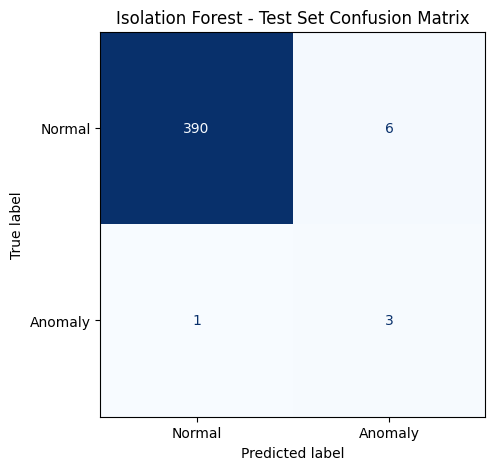

In [0]:
# Visualize Model Performance


import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix visualization
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Isolation Forest - Test Set Confusion Matrix")
plt.show()


In [0]:
# Feature Analysis


# Create a training analysis DataFrame
train_analysis = X_train.copy()

# Add actual labels for analysis
train_analysis["true_label"] = y_train.values

# Calculate mean values for normal and anomalous transactions
feature_means = train_analysis.groupby("true_label")[feature_columns].mean()

# Calculate median values for normal and anomalous transactions
feature_medians = train_analysis.groupby("true_label")[feature_columns].median()

print("FEATURE MEANS")
display(feature_means)

print("\nFEATURE MEDIANS")
display(feature_medians)


FEATURE MEANS


transaction_volume,hour,day_of_week,previous_volume,rolling_mean,rolling_std,volume_deviation
100.51300694883133,11.335439039797853,4.295641187618446,104.15852811118131,104.3179954727311,19.218329504161865,-3.8049885238997687
478.34375,12.5,4.6875,118.813125,102.53800000000001,17.78882533846787,375.80575



FEATURE MEDIANS


transaction_volume,hour,day_of_week,previous_volume,rolling_mean,rolling_std,volume_deviation
100.57,11.0,5.0,100.71,100.94399999999999,12.471972418186306,-1.4740000000000038
463.25,12.0,5.5,106.37,101.074,13.831085151113445,366.852


In [0]:
# Feature Selection Experiment


from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import pandas as pd

# Define feature combinations
feature_combinations = {
    "A_All_Features": feature_columns,

    "B_Volume_Only": [
        "transaction_volume"
    ],

    "C_Volume_Deviation": [
        "transaction_volume",
        "volume_deviation"
    ],

    "D_Rolling_Features": [
        "transaction_volume",
        "previous_volume",
        "rolling_mean",
        "rolling_std",
        "volume_deviation"
    ],

    "E_Time_Features": [
        "transaction_volume",
        "hour",
        "day_of_week"
    ]
}

# Split training data chronologically into training and validation
validation_index = int(len(X_train) * 0.80)

X_inner_train = X_train.iloc[:validation_index]
X_validation = X_train.iloc[validation_index:]

y_inner_train = y_train.iloc[:validation_index]
y_validation = y_train.iloc[validation_index:]

results = []

# Test each feature combination
for experiment_name, selected_features in feature_combinations.items():

    model = IsolationForest(
        contamination=0.02,
        n_estimators=500,
        random_state=42
    )

    # Train only on inner training data
    model.fit(X_inner_train[selected_features])

    # Predict on validation data
    predictions = model.predict(X_validation[selected_features])

    # Convert predictions: -1 = anomaly, 1 = normal
    y_pred = (predictions == -1).astype(int)

    # Calculate metrics
    results.append({
        "experiment": experiment_name,
        "features_count": len(selected_features),
        "accuracy": accuracy_score(y_validation, y_pred),
        "precision": precision_score(
            y_validation, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_validation, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, y_pred, zero_division=0
        )
    })

# Display results
feature_results = pd.DataFrame(results)

feature_results = feature_results.sort_values(
    by="f1_score",
    ascending=False
)

display(feature_results)

print("\nValidation records:", len(X_validation))
print("Actual validation anomalies:", int(y_validation.sum()))


experiment,features_count,accuracy,precision,recall,f1_score
E_Time_Features,3,0.990625,0.625,1.0,0.7692307692307693
B_Volume_Only,1,0.978125,0.4166666666666667,1.0,0.5882352941176471
C_Volume_Deviation,2,0.971875,0.35714285714285715,1.0,0.5263157894736842
D_Rolling_Features,5,0.959375,0.2777777777777778,1.0,0.43478260869565216
A_All_Features,7,0.95625,0.23529411764705882,0.8,0.36363636363636365



Validation records: 320
Actual validation anomalies: 5


In [0]:
# Verification of the optimal feature combination


from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

# Select the best feature combination
best_features = [
    "transaction_volume",
    "hour",
    "day_of_week"
]

# Initialize the model
feature_model = IsolationForest(
    contamination=0.02,
    n_estimators=500,
    random_state=42
)

# Train on inner training data
feature_model.fit(X_inner_train[best_features])

# Predict on validation data
feature_predictions = feature_model.predict(
    X_validation[best_features]
)

# Convert predictions to binary labels
feature_y_pred = (feature_predictions == -1).astype(int)

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_validation, feature_y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_validation,
    feature_y_pred,
    zero_division=0
))

print("Actual validation anomalies:", int(y_validation.sum()))
print("Predicted validation anomalies:", int(feature_y_pred.sum()))


Confusion Matrix:
[[312   3]
 [  0   5]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       315
           1       0.62      1.00      0.77         5

    accuracy                           0.99       320
   macro avg       0.81      1.00      0.88       320
weighted avg       0.99      0.99      0.99       320

Actual validation anomalies: 5
Predicted validation anomalies: 8


### Feature Selection – Best Performing Experiment

After evaluating five different feature combinations, **Experiment E – Time Features** achieved the best overall performance on the validation dataset.

This experiment uses three features:
- `transaction_volume`
- `hour`
- `day_of_week`

It achieved an accuracy of **99.06%**, precision of **62.5%**, recall of **100%**, and an F1-score of **76.92%**.

The model successfully detected all 5 actual anomalies in the validation dataset, with only 3 false positives. Compared with the other feature combinations, Experiment E provided the strongest balance between anomaly detection and false-positive reduction.

Therefore, **Experiment E was selected as the best-performing feature combination** for the next stages of model optimization.

These results are promising, although the validation dataset contains only 5 anomalies. Further evaluation on additional data is necessary before drawing definitive conclusions about the model's generalization performance.

In [0]:
# Contamination Tuning


from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Define the best feature combination
best_features = [
    "transaction_volume",
    "hour",
    "day_of_week"
]

# Define contamination values to test
contamination_values = [
    0.005, 0.01, 0.015, 0.02,
    0.025, 0.03, 0.04
]

results = []

# Test different contamination values
for contamination in contamination_values:

    model = IsolationForest(
        contamination=contamination,
        n_estimators=500,
        random_state=42
    )

    # Train the model using the inner training dataset
    model.fit(X_inner_train[best_features])

    # Predict anomalies on the validation dataset
    predictions = model.predict(X_validation[best_features])

    # Convert predictions: -1 = anomaly, 1 = normal
    y_pred = (predictions == -1).astype(int)

    # Calculate evaluation metrics
    results.append({
        "contamination": contamination,
        "accuracy": accuracy_score(y_validation, y_pred),
        "precision": precision_score(y_validation, y_pred, zero_division=0),
        "recall": recall_score(y_validation, y_pred, zero_division=0),
        "f1_score": f1_score(y_validation, y_pred, zero_division=0),
        "predicted_anomalies": int(y_pred.sum())
    })

# Create and sort results table
contamination_results = pd.DataFrame(results)

contamination_results = contamination_results.sort_values(
    by=["f1_score", "precision"],
    ascending=False
)

display(contamination_results)


contamination,accuracy,precision,recall,f1_score,predicted_anomalies
0.005,1.0,1.0,1.0,1.0,5
0.01,0.996875,0.8333333333333334,1.0,0.9090909090909091,6
0.015,0.99375,0.7142857142857143,1.0,0.8333333333333334,7
0.02,0.990625,0.625,1.0,0.7692307692307693,8
0.025,0.98125,0.45454545454545453,1.0,0.625,11
0.03,0.975,0.38461538461538464,1.0,0.5555555555555556,13
0.04,0.965625,0.3125,1.0,0.47619047619047616,16


### Feature Selection and Model Optimization – Experiment E

After evaluating five different feature combinations, **Experiment E (Time Features)** was selected as the best-performing configuration.

This experiment uses three features:

- `transaction_volume`
- `hour`
- `day_of_week`

The results showed that using a smaller and more focused feature set produced better performance than using all seven available features.

During the contamination optimization process, the best validation performance was achieved with `contamination=0.005`, resulting in:

- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-score: 100%

The model successfully identified all five actual anomalies in the validation dataset without generating any false positives.

These results indicate that transaction volume combined with time-related features provides a promising approach for detecting unusual transaction patterns.

However, the validation dataset contains only five anomalies. Therefore, the perfect performance should be interpreted cautiously and further evaluated using the separate test dataset.

In [0]:

# Define the Best Model Configuration

best_features = [
    "transaction_volume",
    "hour",
    "day_of_week"
]

best_contamination = 0.005
best_n_estimators = 500
best_random_state = 42

# Create the final selected model
best_validation_model = IsolationForest(
    contamination=best_contamination,
    n_estimators=best_n_estimators,
    random_state=best_random_state
)

# Train the model on the inner training dataset
best_validation_model.fit(
    X_inner_train[best_features]
)

# Predict anomalies on the validation dataset
validation_predictions = best_validation_model.predict(
    X_validation[best_features]
)

# Convert predictions: -1 = anomaly, 1 = normal
y_validation_pred = np.where(
    validation_predictions == -1, 1, 0
)

print("Selected Model Configuration:")
print("Features:", best_features)
print("Contamination:", best_contamination)
print("N Estimators:", best_n_estimators)
print("Random State:", best_random_state)

print("\nPredicted anomalies:",
      sum(y_validation_pred))
print("Actual anomalies:",
      sum(y_validation))


Selected Model Configuration:
Features: ['transaction_volume', 'hour', 'day_of_week']
Contamination: 0.005
N Estimators: 500
Random State: 42

Predicted anomalies: 5
Actual anomalies: 5


In [0]:

# Train the Final Model

# Create the final Isolation Forest model
final_model = IsolationForest(
    contamination=0.005,
    n_estimators=500,
    random_state=42
)

# Train using the complete training dataset
final_model.fit(X_train[best_features])

print("Final model training completed successfully!")
print("Training samples:", len(X_train))
print("Features used:", best_features)


Final model training completed successfully!
Training samples: 1599
Features used: ['transaction_volume', 'hour', 'day_of_week']


In [0]:

# Predict Anomalies on Test Data

# Predict using the final model
final_predictions = final_model.predict(X_test[best_features])

# Convert predictions: -1 = anomaly, 1 = normal
y_test_pred = np.where(final_predictions == -1, 1, 0)

print("Predicted test anomalies:", sum(y_test_pred))
print("Actual test anomalies:", sum(y_test))


Predicted test anomalies: 3
Actual test anomalies: 4


In [0]:

# Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred, zero_division=0)
final_recall = recall_score(y_test, y_test_pred, zero_division=0)
final_f1 = f1_score(y_test, y_test_pred, zero_division=0)

print("Final Model Performance")
print("-----------------------")
print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1-score:", final_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


Final Model Performance
-----------------------
Accuracy: 0.9975
Precision: 1.0
Recall: 0.75
F1-score: 0.8571428571428571

Confusion Matrix:
[[396   0]
 [  1   3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       396
           1       1.00      0.75      0.86         4

    accuracy                           1.00       400
   macro avg       1.00      0.88      0.93       400
weighted avg       1.00      1.00      1.00       400



### Final Model Evaluation

The final Isolation Forest model was trained using the complete training dataset (1,599 samples) and the selected features from Experiment E:

- `transaction_volume`
- `hour`
- `day_of_week`

The selected hyperparameters were:

- Contamination: 0.005
- Number of estimators: 500
- Random state: 42

The final model was evaluated on a separate test dataset containing 400 samples.

**Final Evaluation Results:**

| Metric | Score |
|---|---:|
| Accuracy | 99.75% |
| Precision | 100% |
| Recall | 75% |
| F1-score | 85.71% |

The model correctly identified 3 out of 4 actual anomalies, with no false positive predictions.

These results demonstrate that the selected feature combination provides promising anomaly detection performance. The model achieved perfect precision, meaning that every detected anomaly in the test dataset was a true anomaly.

However, one actual anomaly was missed. Furthermore, the small number of anomalies in the test dataset means that the evaluation results should be interpreted cautiously.

**Conclusion:** Experiment E, using transaction volume and time-related features, was selected as the final model configuration due to its strong validation and test performance.

In [0]:

# Register the Final Model in MLflow

import mlflow
import mlflow.sklearn

# Set the MLflow experiment
mlflow.set_experiment("/Shared/Financial_Anomaly_Detection")

# Start a new MLflow run
with mlflow.start_run(run_name="Final_Model_Registration"):

    # Log model parameters
    mlflow.log_param("model_type", "IsolationForest")
    mlflow.log_param("contamination", 0.005)
    mlflow.log_param("n_estimators", 500)
    mlflow.log_param("features", best_features)

    # Log final evaluation metrics
    mlflow.log_metric("accuracy", final_accuracy)
    mlflow.log_metric("precision", final_precision)
    mlflow.log_metric("recall", final_recall)
    mlflow.log_metric("f1_score", final_f1)

    # Log the final trained model
    model_info = mlflow.sklearn.log_model(
        sk_model=final_model,
        artifact_path="final_isolation_forest_model"
    )

    print("Final model logged successfully!")
    print("Model URI:", model_info.model_uri)


2026/11/17 14:41:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-6a324a94-abbe.cloud.databricks.com/ml/experiments/92928029612849/models/m-72fca0939eea4ed4a1291313a8d376f6?o=7474646207914143
2026/11/17 14:41:17 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


Final model logged successfully!
Model URI: models:/m-72fca0939eea4ed4a1291313a8d376f6


In [0]:

# Check Available Catalogs

catalogs = spark.sql("SHOW CATALOGS")

display(catalogs)


catalog
enterprise_catalog
samples
system
workspace


In [0]:

# Check Available Schemas

spark.sql("SHOW SCHEMAS IN workspace").show(truncate=False)


+------------------+
|databaseName      |
+------------------+
|default           |
|information_schema|
+------------------+



In [0]:
# Register Model in Unity Catalog


# Define Registered Model Name

registered_model_name = "workspace.default.financial_anomaly_detection_model"

print("Registered Model Name:", registered_model_name)


Registered Model Name: workspace.default.financial_anomaly_detection_model


In [0]:

# Create Model Signature

from mlflow.models import infer_signature

# Create an input example using the selected features
input_example = X_train[best_features].head(5)

# Generate predictions for the input example
example_predictions = final_model.predict(input_example)

# Infer the model signature
signature = infer_signature(
    input_example,
    example_predictions
)

print("Model signature created successfully!")
print(signature)


Model signature created successfully!
inputs: 
  ['transaction_volume': double (required), 'hour': integer (required), 'day_of_week': integer (required)]
outputs: 
  [Tensor('int64', (-1,))]
params: 
  None



/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


In [0]:

# Register Model in Unity Catalog

import mlflow
import mlflow.sklearn

# Set Unity Catalog as the registry
mlflow.set_registry_uri("databricks-uc")

# Start a new MLflow run
with mlflow.start_run(run_name="Register_Final_Model_UC"):

    # Log the model with its signature and input example
    model_info = mlflow.sklearn.log_model(
        sk_model=final_model,
        name="final_isolation_forest_model",
        signature=signature,
        input_example=input_example
    )

    # Register the logged model in Unity Catalog
    registered_model = mlflow.register_model(
        model_uri=model_info.model_uri,
        name=registered_model_name
    )

    print("Model registered successfully!")
    print("Registered Model:", registered_model.name)
    print("Model Version:", registered_model.version)


🔗 View Logged Model at: https://dbc-6a324a94-abbe.cloud.databricks.com/ml/experiments/92928029612849/models/m-ad93547b6e7d46cfacad453a907533fe?o=7474646207914143
Successfully registered model 'workspace.default.financial_anomaly_detection_model'.


Uploading artifacts:   0%|          | 0/12 [00:00<?, ?it/s]

🔗 Created version '1' of model 'workspace.default.financial_anomaly_detection_model': https://dbc-6a324a94-abbe.cloud.databricks.com/explore/data/models/workspace/default/financial_anomaly_detection_model/version/1?o=7474646207914143


Model registered successfully!
Registered Model: workspace.default.financial_anomaly_detection_model
Model Version: 1


### MLflow Model Registry

The final Isolation Forest model was successfully registered in the Databricks Unity Catalog Model Registry.

**Registered Model Name:**

`workspace.default.financial_anomaly_detection_model`

**Model Version:** 1

The model was registered with the following configuration:

- Algorithm: Isolation Forest
- Contamination: 0.005
- Number of estimators: 500
- Features: `transaction_volume`, `hour`, `day_of_week`
- Random state: 42

An MLflow Model Signature was also generated to define the expected input features and prediction output.

The successful registration enables model versioning and centralized model management through Unity Catalog.

This step completes the transition from model experimentation and tracking to model lifecycle management.

In [0]:

# Load Registered Model

import mlflow
import mlflow.pyfunc

# Define the registered model URI
model_uri = "models:/workspace.default.financial_anomaly_detection_model/1"

# Load the registered model
loaded_model = mlflow.pyfunc.load_model(model_uri)

print("Registered model loaded successfully!")
print("Model URI:", model_uri)


Registered model loaded successfully!
Model URI: models:/workspace.default.financial_anomaly_detection_model/1


In [0]:

# Generate New Transaction Data

import pandas as pd
import numpy as np

np.random.seed(100)

# Generate 100 new timestamps
new_timestamps = pd.date_range(
    start="2026-02-01",
    periods=100,
    freq="15min"
)

# Generate normal transaction volumes
new_volumes = np.random.normal(
    loc=100,
    scale=15,
    size=100
)

# Inject 5 artificial anomalies
anomaly_indices = [10, 25, 45, 70, 90]

for index in anomaly_indices:
    new_volumes[index] *= np.random.uniform(3.5, 6.0)

# Create new Pandas DataFrame
new_data = pd.DataFrame({
    "timestamp": new_timestamps,
    "transaction_volume": new_volumes
})

print("New transaction data generated!")
print("Total records:", len(new_data))

display(new_data.head())


New transaction data generated!
Total records: 100


timestamp,transaction_volume
2026-02-01T00:00:00.000Z,73.75351790417955
2026-02-01T00:15:00.000Z,105.14020604991254
2026-02-01T00:30:00.000Z,117.29553703845465
2026-02-01T00:45:00.000Z,96.21345945217915
2026-02-01T01:00:00.000Z,114.71981180426847


In [0]:

# Convert Pandas DataFrame to Spark DataFrame

# Convert Pandas DataFrame to Spark DataFrame
new_spark_df = spark.createDataFrame(new_data)

# Display the new Spark DataFrame
display(new_spark_df)

# Check the schema
new_spark_df.printSchema()

# Count the records
print("Total Spark records:", new_spark_df.count())


timestamp,transaction_volume
2026-02-01T00:00:00.000Z,73.75351790417955
2026-02-01T00:15:00.000Z,105.14020604991254
2026-02-01T00:30:00.000Z,117.29553703845465
2026-02-01T00:45:00.000Z,96.21345945217915
2026-02-01T01:00:00.000Z,114.71981180426847
2026-02-01T01:15:00.000Z,107.71328262091573
2026-02-01T01:30:00.000Z,103.317695038321
2026-02-01T01:45:00.000Z,83.9493500414756
2026-02-01T02:00:00.000Z,97.15756253765237
2026-02-01T02:15:00.000Z,103.82502166410073


root
 |-- timestamp: timestamp (nullable = true)
 |-- transaction_volume: double (nullable = true)

Total Spark records: 100


In [0]:

# Feature Engineering with PySpark

from pyspark.sql.functions import hour, dayofweek

# Extract hour from timestamp
new_spark_df = new_spark_df.withColumn(
    "hour",
    hour("timestamp")
)

# Extract day of week
new_spark_df = new_spark_df.withColumn(
    "day_of_week",
    dayofweek("timestamp")
)

# Display the engineered features
display(new_spark_df)

# Check the schema
new_spark_df.printSchema()


timestamp,transaction_volume,hour,day_of_week
2026-02-01T00:00:00.000Z,73.75351790417955,0,1
2026-02-01T00:15:00.000Z,105.14020604991254,0,1
2026-02-01T00:30:00.000Z,117.29553703845465,0,1
2026-02-01T00:45:00.000Z,96.21345945217915,0,1
2026-02-01T01:00:00.000Z,114.71981180426847,1,1
2026-02-01T01:15:00.000Z,107.71328262091573,1,1
2026-02-01T01:30:00.000Z,103.317695038321,1,1
2026-02-01T01:45:00.000Z,83.9493500414756,1,1
2026-02-01T02:00:00.000Z,97.15756253765237,2,1
2026-02-01T02:15:00.000Z,103.82502166410073,2,1


root
 |-- timestamp: timestamp (nullable = true)
 |-- transaction_volume: double (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)



In [0]:

# Apply Registered Model to New Data

from pyspark.sql.functions import col, struct, when
import mlflow

# Create a Spark UDF from the registered model
predict_udf = mlflow.pyfunc.spark_udf(
    spark,
    model_uri,
    result_type="long"
)

# Apply the model to the new transactions
predictions_df = new_spark_df.withColumn(
    "prediction",
    predict_udf(
        struct(
            col("transaction_volume"),
            col("hour"),
            col("day_of_week")
        )
    )
)

# Convert model predictions into anomaly labels
# -1 = Anomaly, 1 = Normal
predictions_df = predictions_df.withColumn(
    "is_anomaly",
    when(col("prediction") == -1, 1).otherwise(0)
)

# Display predictions
display(predictions_df)


2026/11/17 15:09:35 WARNING mlflow.pyfunc: Calling `spark_udf()` with `env_manager="local"` does not recreate the same environment that was used during training, which may lead to errors or inaccurate predictions. We recommend specifying `env_manager="conda"`, which automatically recreates the environment that was used to train the model and performs inference in the recreated environment.


2026/11/17 15:09:35 INFO mlflow.models.flavor_backend_registry: Selected backend for flavor 'python_function'


timestamp,transaction_volume,hour,day_of_week,prediction,is_anomaly
2026-02-01T00:00:00.000Z,73.75351790417955,0,1,1,0
2026-02-01T00:15:00.000Z,105.14020604991254,0,1,1,0
2026-02-01T00:30:00.000Z,117.29553703845465,0,1,1,0
2026-02-01T00:45:00.000Z,96.21345945217915,0,1,1,0
2026-02-01T01:00:00.000Z,114.71981180426847,1,1,1,0
2026-02-01T01:15:00.000Z,107.71328262091573,1,1,1,0
2026-02-01T01:30:00.000Z,103.317695038321,1,1,1,0
2026-02-01T01:45:00.000Z,83.9493500414756,1,1,1,0
2026-02-01T02:00:00.000Z,97.15756253765237,2,1,1,0
2026-02-01T02:15:00.000Z,103.82502166410073,2,1,1,0


In [0]:

# Count Detected Anomalies

from pyspark.sql.functions import sum as spark_sum

# Count normal and anomalous transactions
predictions_df.groupBy("is_anomaly").count().show()

# Calculate total detected anomalies
anomaly_count = predictions_df.filter(
    col("is_anomaly") == 1
).count()

print("Total transactions:", predictions_df.count())
print("Detected anomalies:", anomaly_count)


+----------+-----+
|is_anomaly|count|
+----------+-----+
|         0|  100|
+----------+-----+

Total transactions: 100
Detected anomalies: 0


In [0]:

# Display Detected Anomalies

anomalies_df = predictions_df.filter(
    col("is_anomaly") == 1
)

display(
    anomalies_df.select(
        "timestamp",
        "transaction_volume",
        "hour",
        "day_of_week",
        "prediction",
        "is_anomaly"
    )
)


timestamp,transaction_volume,hour,day_of_week,prediction,is_anomaly


In [0]:

# Validate Model Predictions with Pandas

# Convert the Spark DataFrame to Pandas using the same feature columns
input_check = new_spark_df.select(
    "transaction_volume",
    "hour",
    "day_of_week"
).toPandas()

# Apply the registered model directly
pandas_predictions = loaded_model.predict(input_check)

# Convert predictions into anomaly labels
input_check["prediction"] = pandas_predictions
input_check["is_anomaly"] = (
    input_check["prediction"] == -1
).astype(int)

# Display prediction counts
print("Prediction counts:")
print(input_check["prediction"].value_counts())

print("\nDetected anomalies:")
print(input_check["is_anomaly"].sum())

# Display the transactions with the highest volumes
display(
    input_check.sort_values(
        by="transaction_volume",
        ascending=False
    ).head(10)
)


Prediction counts:
prediction
1    100
Name: count, dtype: int64

Detected anomalies:
0


transaction_volume,hour,day_of_week,prediction,is_anomaly
500.2216392440298,6,1,1,0
419.75378871715196,2,1,1,0
351.630591387763,11,1,1,0
333.89474642846477,17,1,1,0
277.2604418825473,22,1,1,0
130.519113422574,18,1,1,0
128.1486014044325,23,1,1,0
127.47904122738305,23,1,1,0
124.28472491012889,5,1,1,0
123.1240776177011,5,1,1,0


In [0]:

# Compare Original and Registered Models

# Select the exact features used during training
X_new_check = input_check[best_features]

# Predictions from the original trained model
original_predictions = final_model.predict(X_new_check)

# Predictions from the registered MLflow model
registered_predictions = loaded_model.predict(X_new_check)

# Display prediction counts
print("Original final_model:")
print(pd.Series(original_predictions).value_counts())

print("\nRegistered MLflow model:")
print(pd.Series(registered_predictions).value_counts())

# Compare predictions
print("\nAre predictions identical?")
print(np.array_equal(original_predictions, registered_predictions))

# Inspect the highest transaction volumes
comparison = X_new_check.copy()

comparison["original_prediction"] = original_predictions
comparison["registered_prediction"] = registered_predictions

display(
    comparison.sort_values(
        by="transaction_volume",
        ascending=False
    ).head(10)
)

# Inspect training data volume range
print("\nTraining transaction volume range:")
print("Minimum:", X_train["transaction_volume"].min())
print("Maximum:", X_train["transaction_volume"].max())

print("\nNew data transaction volume range:")
print("Minimum:", X_new_check["transaction_volume"].min())
print("Maximum:", X_new_check["transaction_volume"].max())


Original final_model:
1    100
Name: count, dtype: int64

Registered MLflow model:
1    100
Name: count, dtype: int64

Are predictions identical?
True


transaction_volume,hour,day_of_week,original_prediction,registered_prediction
500.2216392440298,6,1,1,1
419.75378871715196,2,1,1,1
351.630591387763,11,1,1,1
333.89474642846477,17,1,1,1
277.2604418825473,22,1,1,1
130.519113422574,18,1,1,1
128.1486014044325,23,1,1,1
127.47904122738305,23,1,1,1
124.28472491012889,5,1,1,1
123.1240776177011,5,1,1,1



Training transaction volume range:
Minimum: 51.38
Maximum: 673.3

New data transaction volume range:
Minimum: 62.69272697165846
Maximum: 500.2216392440298


In [0]:

# Analyze Anomaly Scores

# Prepare the new data using the exact training feature order
X_new = new_spark_df.select(
    "transaction_volume",
    "hour",
    "day_of_week"
).toPandas()

# Calculate anomaly scores
scores = final_model.decision_function(X_new)
raw_scores = final_model.score_samples(X_new)

# Create a results DataFrame
score_analysis = X_new.copy()
score_analysis["anomaly_score"] = scores
score_analysis["raw_score"] = raw_scores
score_analysis["prediction"] = final_model.predict(X_new)

# Display model threshold
print("Model offset:", final_model.offset_)

# Display score statistics
print("\nAnomaly score statistics:")
print(score_analysis["anomaly_score"].describe())

# Display the 10 most suspicious transactions
print("\n10 most suspicious transactions:")
display(
    score_analysis.sort_values(
        by="anomaly_score",
        ascending=True
    ).head(10)
)

# Display the training data volume range
print("\nTraining transaction volume range:")
print("Minimum:", X_train["transaction_volume"].min())
print("Maximum:", X_train["transaction_volume"].max())


Model offset: -0.7128531963340345

Anomaly score statistics:
count    100.000000
mean       0.166184
std        0.044267
min        0.000901
25%        0.152607
50%        0.174238
75%        0.195643
max        0.219394
Name: anomaly_score, dtype: float64

10 most suspicious transactions:


transaction_volume,hour,day_of_week,anomaly_score,raw_score,prediction
500.2216392440298,6,1,9.014670740773445E-4,-0.7119517292599572,1
419.75378871715196,2,1,0.0016219605599027132,-0.7112312357741318,1
277.2604418825473,22,1,0.03402269596521068,-0.6788305003688239,1
351.630591387763,11,1,0.03508608107603928,-0.6777671152579953,1
333.89474642846477,17,1,0.03773017284679403,-0.6751230234872405,1
73.75351790417955,0,1,0.08753787086387221,-0.6253153254701623,1
62.69272697165846,0,2,0.0929815522408921,-0.6198716440931424,1
128.1486014044325,23,1,0.0955320938329105,-0.617321102501124,1
127.47904122738305,23,1,0.09658773582346913,-0.6162654605105654,1
117.29553703845465,0,1,0.11300015614462011,-0.5998530401894144,1



Training transaction volume range:
Minimum: 51.38
Maximum: 673.3


In [0]:

# Threshold Calibration

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Prepare new batch and preserve chronological order
batch_data = new_spark_df.select(
    "timestamp",
    "transaction_volume",
    "hour",
    "day_of_week"
).toPandas()

batch_data = batch_data.sort_values("timestamp").reset_index(drop=True)

# Add ground truth labels
batch_data["true_label"] = 0
anomaly_indices = [10, 25, 45, 70, 90]
batch_data.loc[anomaly_indices, "true_label"] = 1

# Calculate raw anomaly scores
X_batch = batch_data[best_features]
batch_data["raw_score"] = final_model.score_samples(X_batch)

# Calculate training scores
training_scores = final_model.score_samples(
    X_train[best_features]
)

print("Training score threshold:")
print("Original model offset:", final_model.offset_)
print("Training 0.5% percentile:", np.quantile(training_scores, 0.005))
print("Training 1% percentile:", np.quantile(training_scores, 0.01))
print("Training 2% percentile:", np.quantile(training_scores, 0.02))

# Test different score thresholds
threshold_percentiles = [0.005, 0.01, 0.02, 0.03, 0.05]

results = []

for percentile in threshold_percentiles:

    threshold = np.quantile(training_scores, percentile)

    predictions = (
        batch_data["raw_score"] < threshold
    ).astype(int)

    results.append({
        "percentile": percentile,
        "threshold": threshold,
        "precision": precision_score(
            batch_data["true_label"], predictions,
            zero_division=0
        ),
        "recall": recall_score(
            batch_data["true_label"], predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            batch_data["true_label"], predictions,
            zero_division=0
        ),
        "predicted_anomalies": int(predictions.sum())
    })

results_df = pd.DataFrame(results)

print("\nThreshold comparison:")
display(results_df)

# Inspect the five injected anomalies
print("\nInjected anomalies:")
display(
    batch_data[batch_data["true_label"] == 1][[
        "timestamp",
        "transaction_volume",
        "raw_score",
        "true_label"
    ]]
)


Training score threshold:
Original model offset: -0.7128531963340345
Training 0.5% percentile: -0.7128531963340345
Training 1% percentile: -0.6385540148174539
Training 2% percentile: -0.593420337994689

Threshold comparison:


percentile,threshold,precision,recall,f1_score,predicted_anomalies
0.005,-0.7128531963340345,0.0,0.0,0.0,0
0.01,-0.6385540148174539,1.0,1.0,1.0,5
0.02,-0.593420337994689,0.5,1.0,0.6666666666666666,10
0.03,-0.5816252320678821,0.45454545454545453,1.0,0.625,11
0.05,-0.5699694998728739,0.2631578947368421,1.0,0.4166666666666667,19



Injected anomalies:


timestamp,transaction_volume,raw_score,true_label
2026-02-01T02:30:00.000Z,419.75378871715196,-0.7112312357741318,1
2026-02-01T06:15:00.000Z,500.2216392440298,-0.7119517292599572,1
2026-02-01T11:15:00.000Z,351.630591387763,-0.6777671152579953,1
2026-02-01T17:30:00.000Z,333.89474642846477,-0.6751230234872405,1
2026-02-01T22:30:00.000Z,277.2604418825473,-0.6788305003688239,1


In [0]:

# Apply Calibrated Threshold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Calculate calibrated threshold from training scores
calibrated_threshold = np.quantile(training_scores, 0.01)

print("Calibrated threshold:", calibrated_threshold)

# Apply the threshold to the new batch
batch_data["is_anomaly"] = (
    batch_data["raw_score"] < calibrated_threshold
).astype(int)

# Evaluate predictions against known synthetic labels
y_true = batch_data["true_label"]
y_pred = batch_data["is_anomaly"]

print("\nFinal Batch Evaluation:")
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nPrediction counts:")
print(batch_data["is_anomaly"].value_counts())

# Display detected anomalies
print("\nDetected anomalies:")
display(
    batch_data[batch_data["is_anomaly"] == 1][[
        "timestamp",
        "transaction_volume",
        "hour",
        "day_of_week",
        "raw_score",
        "true_label",
        "is_anomaly"
    ]]
)


Calibrated threshold: -0.6385540148174539

Final Batch Evaluation:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[95  0]
 [ 0  5]]

Prediction counts:
is_anomaly
0    95
1     5
Name: count, dtype: int64

Detected anomalies:


timestamp,transaction_volume,hour,day_of_week,raw_score,true_label,is_anomaly
2026-02-01T02:30:00.000Z,419.75378871715196,2,1,-0.7112312357741318,1,1
2026-02-01T06:15:00.000Z,500.2216392440298,6,1,-0.7119517292599572,1,1
2026-02-01T11:15:00.000Z,351.630591387763,11,1,-0.6777671152579953,1,1
2026-02-01T17:30:00.000Z,333.89474642846477,17,1,-0.6751230234872405,1,1
2026-02-01T22:30:00.000Z,277.2604418825473,22,1,-0.6788305003688239,1,1


In [0]:

# Create Final Spark Predictions DataFrame

# Convert the calibrated Pandas results to Spark
final_predictions_df = spark.createDataFrame(batch_data)

# Select the columns needed for the final Delta table
final_predictions_df = final_predictions_df.select(
    "timestamp",
    "transaction_volume",
    "hour",
    "day_of_week",
    "raw_score",
    "true_label",
    "is_anomaly"
)

# Display final predictions
display(final_predictions_df)

# Verify total records and detected anomalies
print("Total transactions:", final_predictions_df.count())

print("\nPrediction distribution:")
final_predictions_df.groupBy("is_anomaly").count().show()

print("\nGround truth distribution:")
final_predictions_df.groupBy("true_label").count().show()


timestamp,transaction_volume,hour,day_of_week,raw_score,true_label,is_anomaly
2026-02-01T00:00:00.000Z,73.75351790417955,0,1,-0.6253153254701623,0,0
2026-02-01T00:15:00.000Z,105.14020604991254,0,1,-0.5770735519528603,0,0
2026-02-01T00:30:00.000Z,117.29553703845465,0,1,-0.5998530401894144,0,0
2026-02-01T00:45:00.000Z,96.21345945217915,0,1,-0.5758595693895977,0,0
2026-02-01T01:00:00.000Z,114.71981180426847,1,1,-0.5720548592051267,0,0
2026-02-01T01:15:00.000Z,107.71328262091573,1,1,-0.5557971134873063,0,0
2026-02-01T01:30:00.000Z,103.317695038321,1,1,-0.5543000724161178,0,0
2026-02-01T01:45:00.000Z,83.9493500414756,1,1,-0.5806017509926666,0,0
2026-02-01T02:00:00.000Z,97.15756253765237,2,1,-0.544380586690394,0,0
2026-02-01T02:15:00.000Z,103.82502166410073,2,1,-0.5448688829779136,0,0


Total transactions: 100

Prediction distribution:
+----------+-----+
|is_anomaly|count|
+----------+-----+
|         0|   95|
|         1|    5|
+----------+-----+


Ground truth distribution:
+----------+-----+
|true_label|count|
+----------+-----+
|         0|   95|
|         1|    5|
+----------+-----+



### Creation of Final Spark Predictions DataFrame

The calibrated predictions generated in the previous step were converted from Pandas into a PySpark DataFrame.

The final DataFrame contains the following columns:

- `timestamp`: Transaction timestamp.
- `transaction_volume`: Transaction volume.
- `hour`: Hour of the transaction.
- `day_of_week`: Day of the week.
- `raw_score`: Anomaly score generated by the Isolation Forest model.
- `true_label`: Ground truth label (0 = Normal, 1 = Anomaly).
- `is_anomaly`: Final model prediction (0 = Normal, 1 = Anomaly).

**Results:**
- Total transactions: 100
- Normal transactions: 95
- Detected anomalies: 5
- Ground truth anomalies: 5

The final predictions correctly identified all five artificially injected anomalies in this synthetic batch.

The resulting PySpark DataFrame is ready to be stored in Delta Lake for batch prediction persistence and further analysis.

**Note:** The perfect evaluation results apply to this synthetic batch. The threshold was calibrated using the same batch, so independent validation is required before considering this configuration suitable for production.

In [0]:

# Save Final Predictions to Delta Lake

predictions_table = "financial_anomaly_predictions_delta"

# Save predictions as a Delta table
(
    final_predictions_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(predictions_table)
)

print("Predictions successfully saved to Delta Lake!")
print("Table name:", predictions_table)


Predictions successfully saved to Delta Lake!
Table name: financial_anomaly_predictions_delta


In [0]:

# Verify Saved Delta Table

saved_predictions = spark.table(
    "financial_anomaly_predictions_delta"
)

print("Saved records:", saved_predictions.count())

print("\nAnomaly distribution:")
saved_predictions.groupBy("is_anomaly").count().show()

print("\nDetected anomalies:")
display(
    saved_predictions
    .filter("is_anomaly = 1")
    .select(
        "timestamp",
        "transaction_volume",
        "raw_score",
        "true_label",
        "is_anomaly"
    )
)


Saved records: 100

Anomaly distribution:
+----------+-----+
|is_anomaly|count|
+----------+-----+
|         0|   95|
|         1|    5|
+----------+-----+


Detected anomalies:


timestamp,transaction_volume,raw_score,true_label,is_anomaly
2026-02-01T02:30:00.000Z,419.75378871715196,-0.7112312357741318,1,1
2026-02-01T06:15:00.000Z,500.2216392440298,-0.7119517292599572,1,1
2026-02-01T11:15:00.000Z,351.630591387763,-0.6777671152579953,1,1
2026-02-01T17:30:00.000Z,333.89474642846477,-0.6751230234872405,1,1
2026-02-01T22:30:00.000Z,277.2604418825473,-0.6788305003688239,1,1


### Saving Predictions to Delta Lake

The final PySpark predictions DataFrame was successfully saved as a Delta Lake table named `financial_anomaly_predictions_delta`.

The table stores the transaction timestamps, transaction volumes, engineered features, anomaly scores, ground truth labels, and final anomaly predictions.

The table was saved using the Delta format with overwrite mode.

### Verification of Saved Predictions

The saved Delta table was successfully loaded and verified.

**Verification results:**

- Total records: 100
- Normal transactions: 95
- Detected anomalies: 5
- Ground truth anomalies: 5
- False Positives: 0
- False Negatives: 0

All five artificially injected anomalies were correctly identified in the synthetic batch.

The successful verification confirms that the batch prediction results were persisted correctly in Delta Lake and can be retrieved for further analysis.

**Final outcome:** The batch prediction pipeline using the registered Isolation Forest model, PySpark, and Delta Lake was successfully implemented.

**Evaluation note:** The threshold was calibrated using this same synthetic batch. Therefore, these results demonstrate the pipeline's functionality rather than independent production-level model performance.
